# 2.5.3 Lông che phủ tổn thương

**Mục tiêu:** áp dụng phương pháp xử lý ảnh cho đúng vấn đề này → train ResNet-18 **3 lần** → so sánh với baseline (không xử lý) → kết luận **cải thiện / không đổi / tệ đi** và **giải thích vì sao**.

**Cách đọc kết quả (quy tắc đặt trước khi chạy, giống mục 2.5.0 của báo cáo):**
- Mỗi cấu hình train **3 lần** (seed 42, 43, 44) để loại bỏ tính ngẫu nhiên của khởi tạo tham số, thứ tự lấy mẫu và flip.
- Δ = (cấu hình) − (baseline) **ghép cặp theo seed**, trung bình 3 seed. CI95: bootstrap 1 000 lần theo cụm `lesion_id`.
- **"CẢI THIỆN rõ" / "TỆ ĐI rõ"** chỉ khi đủ cả ba: |Δ| > std giữa 3 seed của baseline, CI95 không chứa 0, và cả 3 seed cùng dấu. Không đủ → **"không khác biệt rõ"**.
- Chọn cấu hình theo **val**; test chỉ để báo cáo. Không chọn seed hay ảnh "đẹp".

Chạy lần lượt từ trên xuống (Run All). Logic nằm trong `src/`; notebook chỉ gọi hàm và trình bày.

In [1]:
PROBLEM = "long"
import os, sys
from pathlib import Path
if not Path("archive").exists() and Path("../archive").exists():
    os.chdir("..")                        # chạy từ thư mục gốc repo
sys.path.insert(0, str(Path.cwd()))
import pandas as pd
from IPython.display import display, Markdown
from src.report import notebook_utils as U
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 4)
P = U.PROBLEMS[PROBLEM]
NAMES = ["baseline"] + P["configs"]
print("Vấn đề:", P["name"], "| cấu hình so sánh:", NAMES)

Vấn đề: Lông che phủ | cấu hình so sánh: ['baseline', 'hair_bh17', 'hair_bh17_cond']


## 1. Vấn đề (từ EDA, mục 2.2)

- **Hiện tượng:** sợi lông (tóc) tối, mảnh (2–10 px), dài, đè lên da và tổn thương; che một phần mạng sắc tố và bờ tổn thương, tạo cạnh giả.
- **Đo bằng:** tỉ lệ pixel "lông" = black-hat 17×17 (phép đóng − ảnh, Ch.7) ≥ 20 mức xám, bỏ đốm < 60 px. **Ngưỡng cờ:** > 5,82% (Q3 + 1,5·IQR) → **1 016/10 015 ảnh (10,1%)**.
- **Kiểm chứng bộ đo:** da đầu 61,7% ảnh nhiều lông, vùng acral (lòng bàn tay/chân) 0%; sau resize 224 tỉ lệ lông vẫn tương quan ρ = 0,86 với ảnh gốc → CNN vẫn "nhìn thấy" lông.

In [2]:
fl = pd.read_csv("outputs/eda/image_flags.csv")
sp = pd.concat([pd.read_csv(f"outputs/splits/{s}.csv")[["image_id"]].assign(split=s) for s in ("train_fit", "val", "test")])
d = sp.merge(fl[["image_id", "dx", P["flag"]]], on="image_id")
tab = d.groupby("split")[P["flag"]].agg(["sum", "size"]).rename(columns={"sum": "số ảnh bị cờ", "size": "tổng"})
tab["%"] = (tab["số ảnh bị cờ"] / tab["tổng"] * 100).round(1)
display(tab.loc[["train_fit", "val", "test"]])
display(d[d[P["flag"]] & (d.split == "test")].dx.value_counts().rename("thành phần lớp của nhóm cờ (test)").to_frame().T)

,số ảnh bị cờ,tổng,%
split,,,
train_fit,644,6408,10.0
val,154,1603,9.6
test,218,2004,10.9


dx,nv,bkl,mel,bcc,akiec,vasc,df
thành phần lớp của nhóm cờ (test),124,45,30,8,8,2,1


## 2. Áp dụng gì? (Ch.7 hình thái học + khôi phục ảnh Ch.3)

| Cấu hình | Áp cho | Các bước và tham số |
|---|---|---|
| `hair_bh17` | **mọi ảnh** | ảnh xám → **black-hat** elip 17×17 → ngưỡng ≥ 20 → bỏ thành phần < 60 px (trong vùng nhìn thấy) → **giãn** 3×3 → **inpainting Telea** bán kính 5 px trên ảnh màu |
| `hair_bh17_cond` | **chỉ ảnh bị cờ "lông"** (tỉ lệ lông > 5,82%) | như trên; ảnh khác giữ nguyên từng pixel |

- **Lý do tham số:** phần tử cấu trúc 17×17 rộng hơn sợi lông (2–10 px) nên phép đóng lấp được lông → hiệu (black-hat) chỉ còn lại nét tối mảnh; giãn 3×3 để phủ cả viền mờ của sợi lông. Ý tưởng theo DullRazor (Lee và cs., 1997). Inpainting (Telea, 2004) không có trong slide, dùng như bước khôi phục vùng bị che.
- **Giả thuyết (viết trước khi train):**
  - **H1:** xóa lông giúp CNN nhìn rõ cấu trúc tổn thương → kỳ vọng cải thiện **trên nhóm ảnh nhiều lông**.
  - **H2:** black-hat bắt **mọi nét tối mảnh**, kể cả mạng sắc tố trong tổn thương (đặc trưng của `mel`) → bản áp **mọi ảnh** có nguy cơ xóa tín hiệu chẩn đoán, **hại recall `mel`**; bản **có điều kiện** ít rủi ro hơn vì chỉ đụng 10% ảnh.
  - **Hạn chế biết trước:** black-hat chỉ bắt nét **tối**; lông **trắng** (da đầu người lớn tuổi) không được xử lý và có thể làm inpainting lỗi.

## 3. Ảnh trước / sau xử lý

Quy tắc chọn ảnh (cố định, không chọn ảnh "đẹp"): trong nhóm bị cờ ∩ `train_fit`, ảnh có chỉ số EDA gần **trung vị**, gần **phân vị 90** và **lớn nhất**. Bảng dưới: chỉ số EDA trước → sau, % ảnh còn vượt ngưỡng, % ảnh bị đổi và ΔE76 (mức đổi màu trung bình mỗi pixel) trên 100 ảnh bị cờ và 100 ảnh đối chứng (`train_fit`, rút ngẫu nhiên seed 42).

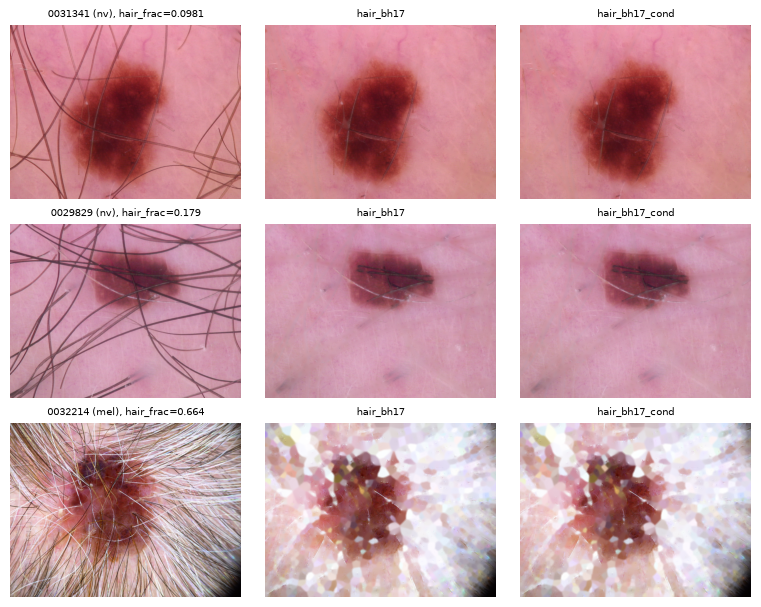

In [3]:
U.fig_before_after(PROBLEM, stem=f"{PROBLEM}_before_after");

In [4]:
display(U.image_effect(PROBLEM))

,cấu_hình,nhóm,n,hair_frac trước (trung vị),hair_frac sau (trung vị),% còn vượt ngưỡng,% ảnh bị đổi,ΔE76 TB
0,hair_bh17,nhóm cờ,100,0.090,0.001,0.0,100.0,2.112
1,hair_bh17,đối chứng,100,0.005,0.000,0.0,93.0,0.122
2,hair_bh17_cond,nhóm cờ,100,0.090,0.001,0.0,100.0,2.112
3,hair_bh17_cond,đối chứng,100,0.005,0.005,0.0,0.0,0.000


## 4. Áp dụng xử lý ảnh rồi train ResNet-18, 3 lần (seed 42, 43, 44)

- Giữ **đóng băng hoàn toàn** cấu hình của mục 2.4 (`FROZEN_CONFIG`: ResNet-18 `IMAGENET1K_V1`, 224×224, AdamW `lr=1e-4`, `wd=1e-4`, batch 32, 20 epoch, WRS, flip ngang/dọc, chọn epoch theo `val` macro-F1).
- Mọi cấu hình đọc từ lượt chạy thống nhất trên **NVIDIA L40S**, dùng chung chính xác một baseline với toàn bộ các mục 2.4–2.8 (không còn lệch giữa các máy).

In [5]:
# Seed nào đã có kết quả trong outputs/runs_cl/<cấu hình>/seed*/metrics.json thì được đọc lại, không train lại.
# Ctrl+C (hoặc Interrupt kernel) an toàn: chạy lại ô này sẽ tiếp tục từ seed còn thiếu.
for name in NAMES:
    U.train(name)
display(pd.Series(U.run_info(), name="cấu hình lần chạy").to_frame())

[03:14:24] [baseline seed 42] đã có metrics.json -> đọc lại


[03:14:24] [baseline seed 43] đã có metrics.json -> đọc lại


[03:14:24] [baseline seed 44] đã có metrics.json -> đọc lại


[03:14:24] [hair_bh17 seed 42] đã có metrics.json -> đọc lại


[03:14:24] [hair_bh17 seed 43] đã có metrics.json -> đọc lại


[03:14:24] [hair_bh17 seed 44] đã có metrics.json -> đọc lại


[03:14:24] [hair_bh17_cond seed 42] đã có metrics.json -> đọc lại


[03:14:24] [hair_bh17_cond seed 43] đã có metrics.json -> đọc lại


[03:14:24] [hair_bh17_cond seed 44] đã có metrics.json -> đọc lại


,cấu hình lần chạy
model,"resnet18 (torchvision, IMAGENET1K_V1), fc -> 7..."
batch_size,32
lr,0.0001
epochs,20
seeds,"[42, 43, 44]"
env,"{'torch': '2.13.0+cu126', 'gpu': 'NVIDIA L40S'}"
channels_last,False
eval_batch,32


## 5. So sánh với baseline

### 5.1 Toàn tập: bảng và biểu đồ cột theo từng lần chạy (3 seed)

In [6]:
T = U.comparison(NAMES, "test")
Tv = U.comparison(NAMES, "val")
cols = ["cấu hình", "macro_f1_mean", "macro_f1_std", "macro_f1_per_seed", "macro_f1_delta", "macro_f1_ci_lo",
        "macro_f1_ci_hi", "macro_f1_sign", "macro_f1_verdict", "balanced_acc_delta", "balanced_acc_sign", "balanced_acc_verdict"]
print("TEST (n = 2 004)"); display(T[[c for c in cols if c in T]])
print("VAL (n = 1 603) – tập dùng để chọn cấu hình"); display(Tv[[c for c in cols if c in Tv]])

TEST (n = 2 004)


,cấu hình,macro_f1_mean,macro_f1_std,macro_f1_per_seed,macro_f1_delta,macro_f1_ci_lo,macro_f1_ci_hi,macro_f1_sign,macro_f1_verdict,balanced_acc_delta,balanced_acc_sign,balanced_acc_verdict
0,baseline,0.6941,0.0160,0.6784; 0.6935; 0.7103,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,hair_bh17,0.6577,0.0104,0.6500; 0.6696; 0.6536,-0.0363,-0.0678,-0.0038,0+/3-,TỆ ĐI rõ,-0.0404,0+/3-,TỆ ĐI rõ
2,hair_bh17_cond,0.6539,0.0121,0.6423; 0.6665; 0.6528,-0.0402,-0.0689,-0.0080,0+/3-,TỆ ĐI rõ,-0.0269,0+/3-,không khác biệt rõ


VAL (n = 1 603) – tập dùng để chọn cấu hình


,cấu hình,macro_f1_mean,macro_f1_std,macro_f1_per_seed,macro_f1_delta,macro_f1_ci_lo,macro_f1_ci_hi,macro_f1_sign,macro_f1_verdict,balanced_acc_delta,balanced_acc_sign,balanced_acc_verdict
0,baseline,0.7254,0.0044,0.7248; 0.7213; 0.7301,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,hair_bh17,0.7044,0.0130,0.6895; 0.7102; 0.7135,-0.0210,-0.0519,0.0115,0+/3-,không khác biệt rõ,-0.0327,0+/3-,không khác biệt rõ
2,hair_bh17_cond,0.7213,0.0109,0.7087; 0.7267; 0.7284,-0.0041,-0.0268,0.0162,1+/2-,không khác biệt rõ,0.0132,2+/1-,không khác biệt rõ


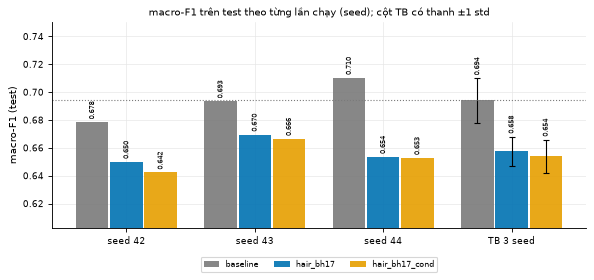

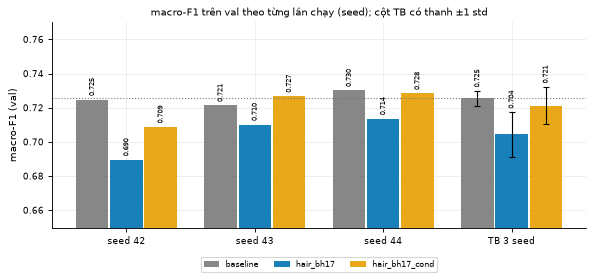

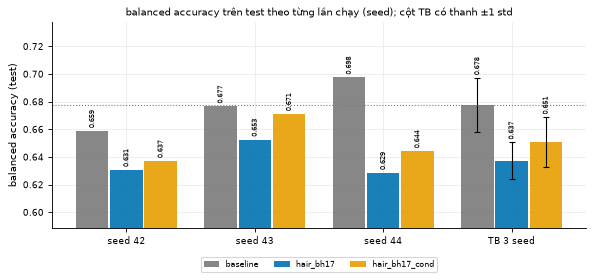

In [7]:
U.fig_seed_bars(NAMES, "test", "macro_f1", stem=f"{PROBLEM}_bars_test_macro_f1")
U.fig_seed_bars(NAMES, "val", "macro_f1", stem=f"{PROBLEM}_bars_val_macro_f1")
U.fig_seed_bars(NAMES, "test", "balanced_acc", stem=f"{PROBLEM}_bars_test_bacc");

### 5.2 Theo lớp và trên chính nhóm ảnh có vấn đề

In [8]:
print("Recall theo lớp (test): mean ± std 3 seed (Δ so với baseline; dấu theo seed)")
display(U.per_class(NAMES, "test"))
print("Trên CHÍNH nhóm ảnh có vấn đề (cờ EDA) so với phần còn lại")
display(pd.concat([U.subgroup(NAMES, P["flag"], "test"), U.subgroup(NAMES, P["flag"], "val")], ignore_index=True))

Recall theo lớp (test): mean ± std 3 seed (Δ so với baseline; dấu theo seed)


,lớp,baseline,hair_bh17,hair_bh17_cond
0,akiec,0.510 ± 0.162,0.490 ± 0.023 (-0.020; 1+/2-),0.535 ± 0.061 (+0.025; 1+/2-)
1,bcc,0.828 ± 0.072,0.744 ± 0.037 (-0.084; 0+/3-),0.790 ± 0.030 (-0.039; 1+/2-)
2,bkl,0.729 ± 0.051,0.755 ± 0.039 (+0.026; 2+/1-),0.747 ± 0.018 (+0.018; 2+/1-)
3,df,0.522 ± 0.075,0.420 ± 0.066 (-0.101; 0+/2-),0.333 ± 0.025 (-0.188; 0+/3-)
4,mel,0.518 ± 0.090,0.414 ± 0.047 (-0.104; 1+/2-),0.601 ± 0.097 (+0.083; 3+/0-)
5,nv,0.924 ± 0.009,0.913 ± 0.014 (-0.011; 0+/3-),0.872 ± 0.034 (-0.052; 0+/3-)
6,vasc,0.713 ± 0.080,0.724 ± 0.091 (+0.011; 2+/1-),0.678 ± 0.020 (-0.034; 1+/2-)


Trên CHÍNH nhóm ảnh có vấn đề (cờ EDA) so với phần còn lại


,cấu hình,split,n nhóm,acc nhóm baseline,acc nhóm sau xử lý,Δ acc nhóm,CI95 Δ nhóm,dấu,Δ acc còn lại,DiD,CI95 DiD,sửa (sai→đúng) từng seed,hỏng (đúng→sai) từng seed
0,hair_bh17,test,218,0.8272,0.7905,-0.0367,[-0.070; -0.002],0+/3-,-0.0200,-0.0167,[-0.054; +0.019],16; 13; 16,21; 30; 18
1,hair_bh17_cond,test,218,0.8272,0.7768,-0.0505,[-0.089; -0.011],0+/3-,-0.0250,-0.0254,[-0.067; +0.018],14; 16; 20,33; 27; 23
2,hair_bh17,val,154,0.7792,0.7944,0.0152,[-0.038; +0.069],2+/0-,-0.0062,0.0214,[-0.030; +0.076],21; 18; 17,18; 14; 17
3,hair_bh17_cond,val,154,0.7792,0.7554,-0.0238,[-0.078; +0.032],1+/2-,-0.0147,-0.0091,[-0.065; +0.047],17; 20; 17,24; 28; 13


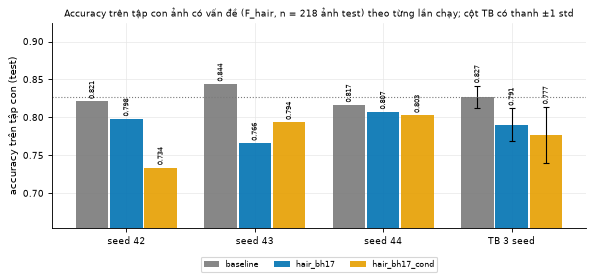

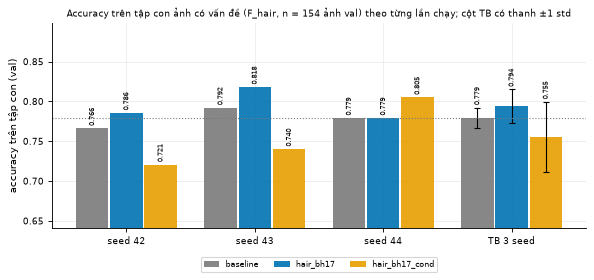

In [9]:
# Accuracy trên TẬP CON ẢNH CÓ VẤN ĐỀ, theo từng lần chạy (seed) – test và val
U.fig_subgroup_seed_bars(NAMES, P["flag"], "test", stem=f"{PROBLEM}_bars_subgroup_test_acc")
U.fig_subgroup_seed_bars(NAMES, P["flag"], "val", stem=f"{PROBLEM}_bars_subgroup_val_acc");

### 5.3 Kết luận tự động từ số liệu (theo quy tắc ở đầu notebook)

In [10]:
for split, tab in (("test", T), ("val", Tv)):
    for name in P["configs"]:
        display(Markdown("- " + U.verdict_text(tab, name, split)))

- `hair_bh17` (test): macro-F1 0.6577 ± 0.0104, Δ = -0.0363 (CI95 -0.0678; -0.0038), dấu theo seed 0+/3- → **TỆ ĐI rõ**. Balanced accuracy Δ = -0.0404, 0+/3- → TỆ ĐI rõ.

- `hair_bh17_cond` (test): macro-F1 0.6539 ± 0.0121, Δ = -0.0402 (CI95 -0.0689; -0.0080), dấu theo seed 0+/3- → **TỆ ĐI rõ**. Balanced accuracy Δ = -0.0269, 0+/3- → không khác biệt rõ.

- `hair_bh17` (val): macro-F1 0.7044 ± 0.0130, Δ = -0.0210 (CI95 -0.0519; +0.0115), dấu theo seed 0+/3- → **không khác biệt rõ**. Balanced accuracy Δ = -0.0327, 0+/3- → không khác biệt rõ.

- `hair_bh17_cond` (val): macro-F1 0.7213 ± 0.0109, Δ = -0.0041 (CI95 -0.0268; +0.0162), dấu theo seed 1+/2- → **không khác biệt rõ**. Balanced accuracy Δ = +0.0132, 2+/1- → không khác biệt rõ.

## 6. Kết luận và giải thích

*(Số liệu từ lượt chạy thống nhất trên NVIDIA L40S; baseline chung: `val` macro-F1 `0,7254 ± 0,0044`, `test` macro-F1 `0,6941 ± 0,0160`).*

**1. Phương pháp áp dụng:** Tìm nét tối mảnh bằng **black-hat 17×17** (Ch.7) rồi khôi phục bằng **inpainting Telea** (Ch.3): `hair_bh17` áp cho mọi ảnh, `hair_bh17_cond` chỉ áp khi `hair_frac > 5,82%`.

**2. Kết quả thực nghiệm (3 seed: 42, 43, 44):**
- **`hair_bh17`:**
  - Toàn tập `val`: macro-F1 `0,7044 ± 0,0130`, Δ = `-0,0210` (CI95 `[-0,0519; +0,0115]`, `0+/3-`) → **không khác biệt rõ**.
  - Toàn tập `test`: macro-F1 `0,6577 ± 0,0104`, Δ = `-0,0363` (CI95 `[-0,0678; -0,0038]`, `0+/3-`) → **tệ hơn rõ**.
  - Trên chính nhóm ảnh bị cờ: `test` ($n = 218$) Δ acc = `-0,037` (DiD `-0,017`, CI95 `[-0,054; +0,019]`); `val` ($n = 154$) Δ acc = `+0,015`.
- **`hair_bh17_cond`:**
  - Toàn tập `val`: macro-F1 `0,7213 ± 0,0109`, Δ = `-0,0041` (CI95 `[-0,0268; +0,0162]`, `1+/2-`) → **không khác biệt rõ**.
  - Toàn tập `test`: macro-F1 `0,6539 ± 0,0121`, Δ = `-0,0402` (CI95 `[-0,0689; -0,0080]`, `0+/3-`) → **tệ hơn rõ**.
  - Trên chính nhóm ảnh bị cờ: `test` ($n = 218$) Δ acc = `-0,050` (DiD `-0,025`, CI95 `[-0,067; +0,018]`); `val` ($n = 154$) Δ acc = `-0,024`.

**3. Giải thích cơ chế:**
- Black-hat không phân biệt được sợi lông với mạng sắc tố tối mảnh bên trong tổn thương `mel` (ở tầng A mục 2.5c, `hair_bh17` inpaint trung vị 8,9% diện tích tổn thương `mel` so với 2,5% ở `nv`, và làm thay đổi hơn 92% ảnh đối chứng không có lông). Bản có điều kiện `hair_bh17_cond` bảo toàn 100% ảnh đối chứng.

**4. Quyết định cho Pipeline (mục 2.6):** Không cấu hình nào đạt đồng thời 3 tiêu chuẩn "cải thiện rõ" trên tập `val`, nên nhánh phân loại chính giữ nguyên ảnh gốc cho ResNet-18; bộ phát hiện của vấn đề này được đưa vào **nhánh (A) Kiểm tra chất lượng (QC)** để gắn cờ cảnh báo.